# PIKART


## Shared ROI


In [1]:
CATALOG = 'PIKART'
OUTPUT_NAME = 'pikart'
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / 'HOME_PROJECT.json').is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from tools import rotated_analysis as rotated, casr_daily as daily
from tools import rotated_plot_style as plot_style
from tools import catalog_comparison as comparison
comparison.apply_plot_style()
cfg = json.loads((ROOT / 'config.json').read_text())

# Editable controls: UTC, with an exclusive end.
START = pd.Timestamp('1980-01-01 00:00')
END = pd.Timestamp('1985-01-01 00:00')
SNAPSHOT_START = pd.Timestamp('1980-01-19 06:00')
SAMPLE_START = START
SAMPLE_END = min(START + pd.Timedelta(days=7), END)
TRACK_ID = None

grid = rotated.prepare_grid(ROOT, cfg)
OUTPUT = rotated.output_directory(ROOT, grid, OUTPUT_NAME)
OUTPUT.mkdir(parents=True, exist_ok=True)

def show(fig, filename):
    plot_style.finish(fig, filename)
    fig.savefig(OUTPUT / filename, dpi=180, facecolor='white')
    plt.show()
    plt.close(fig)

display(rotated.grid_description(grid).to_frame())
print(f'Analysis: {START:%Y-%m-%d} to {END:%Y-%m-%d} (exclusive), UTC.')

,Shared ROI
Native rows × columns,418 × 260
Local row / column positions (stop excluded),[0:418] / [0:260]
Included cells,108680
Rotated latitude centres (°),-29.07 to 8.46
Rotated longitude centres (°),-30.00 to -6.69
rlat cell-edge bounds (°),-29.115002 to 8.505000
rlon cell-edge bounds (°),-30.042221 to -6.642220
Land / ocean / inland water cells,70551 / 37286 / 843


Analysis: 1980-01-01 to 1985-01-01 (exclusive), UTC.


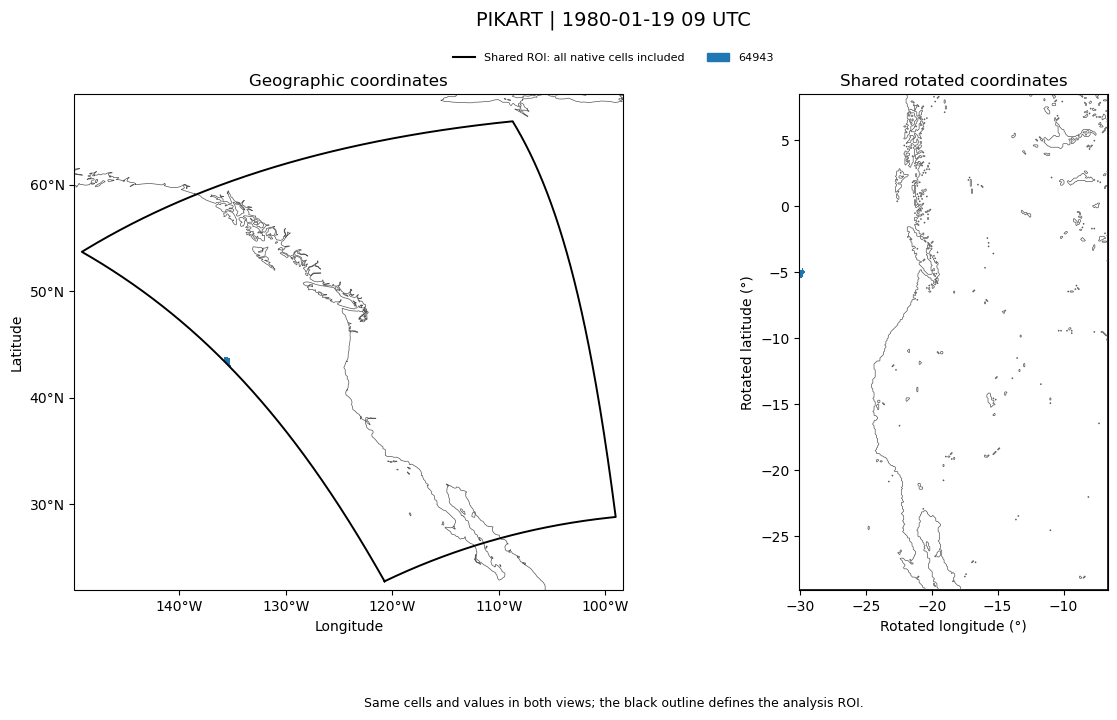

In [2]:
timestamp = SNAPSHOT_START + (pd.Timedelta(hours=3) if CATALOG == 'PIKART' else pd.Timedelta(0))
field, world = rotated.snapshot(ROOT, cfg, grid, CATALOG, timestamp)
show(rotated.plot_coordinate_views(grid, field,
     f'{CATALOG} | {timestamp:%Y-%m-%d %H} UTC', categorical=True),
     '01_roi_coordinates.png')

## Global context


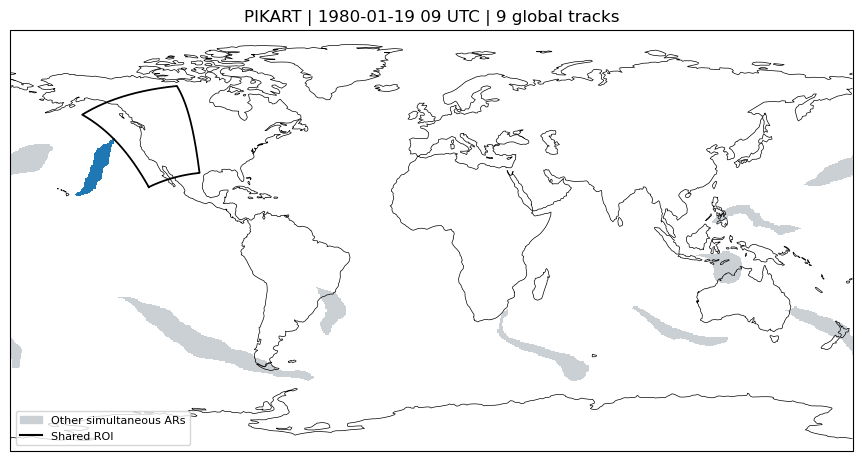

In [3]:
show(rotated.plot_global(grid, world, timestamp, CATALOG,
     np.unique(field[field > 0])), '02_global_context.png')

## Counts and tracking


In [4]:
events = rotated.catalog_analysis(ROOT, cfg, grid, CATALOG, START, END)
display(rotated.catalog_summary(events).to_frame())
failed = events['tracks'].loc[~events['tracks'].verified, ['track_id', 'issue']]
if len(failed):
    display(failed)
else:
    print('All selected IDs pass the catalog consistency checks.')
audit = events['audit']
display(pd.Series({
    'Tracks represented on CaSR grid': audit['native_sampled_tracks'],
    'Source-centre tracks inside the native perimeter': audit['source_centres_inside_tracks'],
    'Inside source-centre tracks not sampled': audit['source_tracks_not_sampled'],
    'Sampled tracks with source centres outside perimeter': audit['sampled_tracks_without_inside_source_centre']
}, name='Sampling audit').to_frame())

PIKART native ROI: 1980
PIKART native ROI: 1981
PIKART native ROI: 1982
PIKART native ROI: 1983
PIKART native ROI: 1984


,PIKART
Distinct tracks in shared ROI,754.000000
Internally consistent tracks,754.000000
Tracks with unresolved checks,0.000000
Single global detection,0.000000
Median global observed span (h),72.000000
Median detections in ROI,4.000000
Mean six-hour AR area coverage (%),2.505481


All selected IDs pass the catalog consistency checks.


,Sampling audit
Tracks represented on CaSR grid,754
Source-centre tracks inside the native perimeter,739
Inside source-centre tracks not sampled,0
Sampled tracks with source centres outside perimeter,15


## Event examples


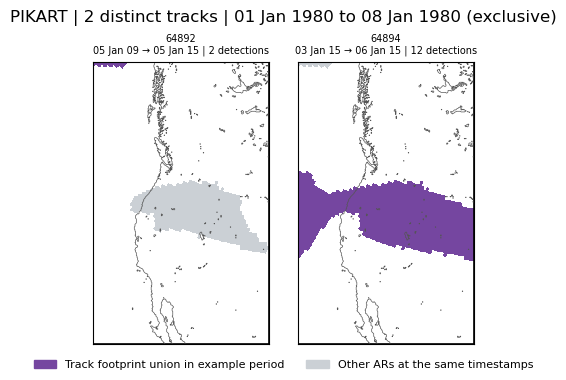

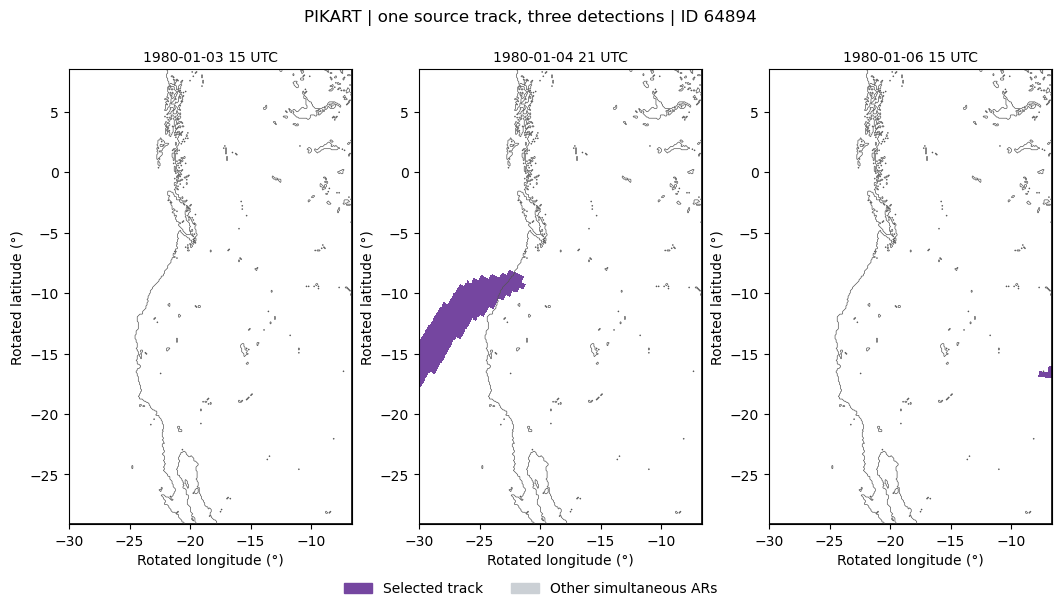

In [5]:
show(rotated.plot_short_gallery(ROOT, cfg, grid, CATALOG, events, SAMPLE_START, SAMPLE_END),
     '03_short_event_gallery.png')
eligible = events['tracks'].loc[lambda f: f.verified & (f.global_detections >= 3) & (f.roi_detections >= 3)]
if TRACK_ID is not None and str(TRACK_ID) not in set(eligible.track_id):
    raise ValueError('Choose a consistent track ID with at least three ROI detections.')
show(rotated.plot_event_samples(ROOT, cfg, grid, CATALOG, events, TRACK_ID),
     '04_one_track_three_detections.png')

## Duration and persistence


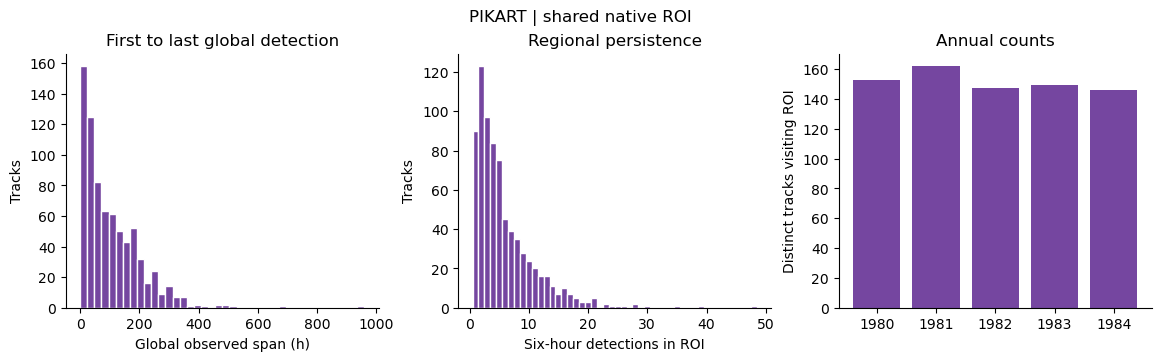

,span_hours,global_detections,roi_detections
count,754.0,754.0,754.0
mean,102.0,17.8,5.9
std,98.4,16.3,5.3
min,6.0,2.0,1.0
25%,24.0,5.0,2.0
50%,72.0,13.0,4.0
75%,156.0,27.0,8.0
max,942.0,157.0,48.0


In [6]:
show(rotated.plot_catalog_statistics(events), '05_event_statistics.png')
verified = events['tracks'].loc[events['tracks'].verified]
display(verified[['span_hours', 'global_detections', 'roi_detections']]
        .describe(percentiles=[0.25, 0.5, 0.75]).round(1))

## Catalog comparison


In [7]:
other_name = 'PIKART' if CATALOG == 'tARget' else 'tARget'
other_manifest = OUTPUT.parent / other_name.lower() / 'catalog_manifest.json'
if other_manifest.exists():
    other = rotated.load_catalog(other_manifest.parent)
    inputs = json.loads(other_manifest.read_text())['inputs']
    assert inputs['start'] == str(START) and inputs['end'] == str(END)
    assert inputs['grid_hash'] == rotated.ar.grid_hash(grid)
    comparison_table = pd.concat([rotated.catalog_summary(events), rotated.catalog_summary(other)], axis=1)
    display(comparison_table[['tARget', 'PIKART']].round(2))
    comparison_table.to_csv(OUTPUT / 'catalog_comparison.csv')
else:
    print(f'Run the {other_name} notebook to populate the shared comparison.')

,tARget,PIKART
Distinct tracks in shared ROI,1565.00,754.00
Internally consistent tracks,1565.00,754.00
Tracks with unresolved checks,0.00,0.00
Single global detection,422.00,0.00
Median global observed span (h),18.00,72.00
Median detections in ROI,3.00,4.00
Mean six-hour AR area coverage (%),9.07,2.51
